Folie 8

In [1]:
import numpy as np
from scipy.stats.contingency import margins

joint_probability_X_Y = np.array([
                [0.01, 0.02, 0.04, 0.04],
                [0.03, 0.24, 0.15, 0.06],
                [0.04, 0.10, 0.08, 0.08],
                [0.02, 0.04, 0.03, 0.02]
            ])


x, y = margins(joint_probability_X_Y)

print(x.T)

[[0.11 0.48 0.3  0.11]]


Folie 24 Mehrdimensionale Normalverteilung

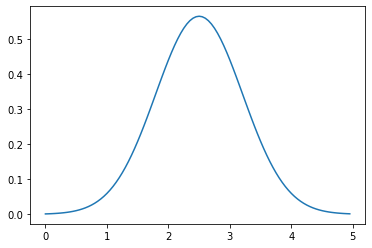

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal

x = np.linspace(0, 5, 100, endpoint=False)
y = multivariate_normal.pdf(x, mean=2.5, cov=0.5)
plt.plot(x, y)
plt.show()

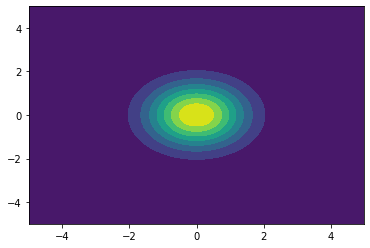

In [3]:
x, y = np.mgrid[-5:5:.01, -5:5:.01]
pos = np.dstack((x, y))
rv = multivariate_normal([0, 0], [[1, 0],
                                  [0, 1]])
plt.contourf(x, y, rv.pdf(pos))
plt.show()

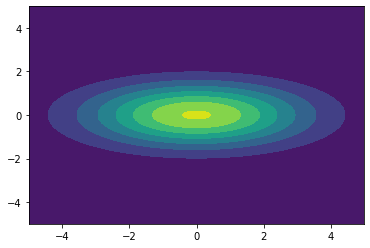

In [4]:
rv = multivariate_normal([0, 0], [[5, 0],
                                  [0, 1]])
plt.contourf(x, y, rv.pdf(pos))
plt.show()

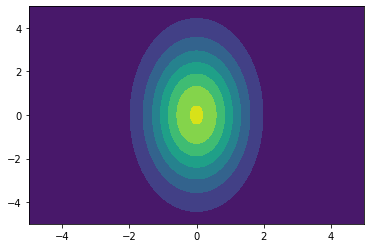

In [16]:
rv = multivariate_normal([0, 0], [[1, 0],
                                  [0, 5]])
plt.contourf(x, y, rv.pdf(pos))
plt.show()

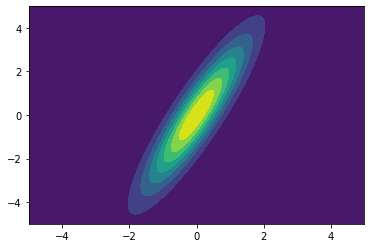

In [19]:
rv = multivariate_normal([0, 0], [[1, 2],
                                  [2, 5]])
plt.contourf(x, y, rv.pdf(pos))
plt.show()

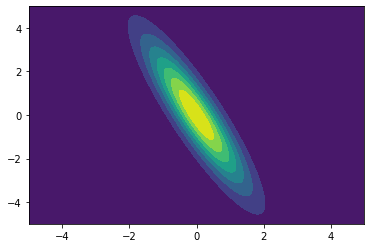

In [20]:
rv = multivariate_normal([0, 0], [[1, -2],
                                  [-2, 5]])
plt.contourf(x, y, rv.pdf(pos))
plt.show()

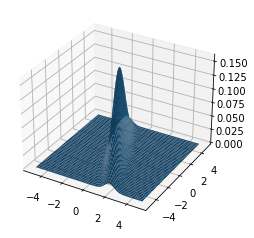

In [21]:
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(x, y, rv.pdf(pos))

Folie 25 Mehrdimensionale Normalverteilung und Randverteilungen

In [23]:
import numpy as np

def univariate_normal(x, mean, variance):
    """pdf of the univariate normal distribution."""
    return ((1. / np.sqrt(2 * np.pi * variance)) * 
            np.exp(-(x - mean)**2 / (2 * variance)))

def multivariate_normal_1(x, mean, covariance):
    """pdf of the multivariate normal distribution."""    
    x_m = x - mean
    return (1. / (np.sqrt((2 * np.pi)**d * np.linalg.det(covariance))) * 
            np.exp(-(np.linalg.solve(covariance, x_m).T.dot(x_m)) / 2))

from scipy.stats import multivariate_normal

def generate_multivariate_normal_2(pos, mean, covariance):
    pdf = multivariate_normal.pdf(pos, mean, covariance)
    return pdf 

In [24]:
d = 2  # dimensions
mean = [0., 1.]

cov = [[1, 0.9], 
       [0.9, 2]]

# Get the mean values from the vector
mean_x = mean[0]
mean_y = mean[1]
# Get the blocks (single values in this case) from 
#  the covariance matrix
var_x = cov[0][0]
var_y = cov[1][1]

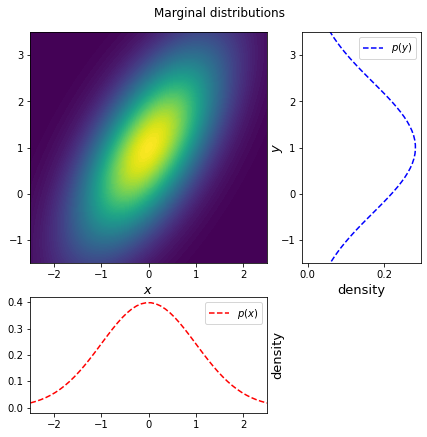

In [27]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

min, max = -5.,5.
x_min, x_max,  = -2.5, 2.5
y_min,y_max = -1.5, 3.5
nb_of_x = 100 # grid size

# Plot the conditional distributions
fig = plt.figure(figsize=(7, 7))
gs = gridspec.GridSpec(
    2, 2, width_ratios=[2, 1], height_ratios=[2, 1])
plt.suptitle('Marginal distributions', y=0.93)

# Plot surface on top left
ax1 = plt.subplot(gs[0])

x, y = np.mgrid[min:max:.01, min:max:.01]
pos = np.dstack((x, y))
pdf = generate_multivariate_normal_2(pos, mean, cov)
# Plot bivariate distribution
con = ax1.contourf(x, y, pdf, levels = nb_of_x)
ax1.set_xlabel('$x$', fontsize=13)
ax1.set_ylabel('$y$', fontsize=13)
ax1.yaxis.set_label_position('right')
ax1.axis([x_min, x_max, y_min, y_max])

# Plot y
ax2 = plt.subplot(gs[1])
y = np.linspace(min, max, num=nb_of_x)
py = univariate_normal(y, mean_y, var_y)
# Plot univariate distribution
ax2.plot(py, y, 'b--', label=f'$p(y)$')
ax2.legend(loc=0)
ax2.set_xlabel('density', fontsize=13)
ax2.set_ylim(y_min, y_max)

# Plot x
ax3 = plt.subplot(gs[2])
x = np.linspace(min, max, num=nb_of_x)
px = univariate_normal(x, mean_x, var_x)
# Plot univariate distribution
ax3.plot(x, px, 'r--', label=f'$p(x)$')
ax3.legend(loc=0)
ax3.set_ylabel('density', fontsize=13)
ax3.yaxis.set_label_position('right')
ax3.set_xlim(x_min, x_max)

plt.show()

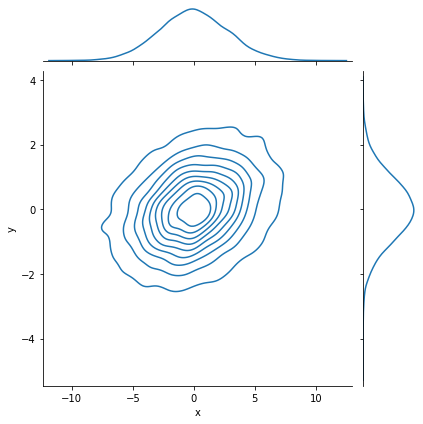

In [31]:
import pandas as pd
import seaborn as sns

mean = [0, 0]
cov = [[8, 0.8], 
       [0.8, 1]]
x, y = np.random.multivariate_normal(mean, cov, 10000).T
df = pd.DataFrame({"x":x, "y":y})

g = sns.jointplot(x="x", y="y", data=df, kind="kde")

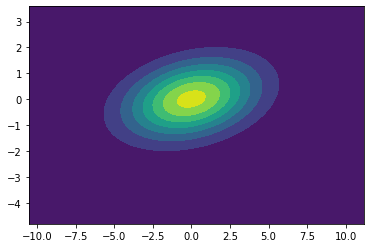

In [32]:
from sklearn.covariance import EmpiricalCovariance
import scipy.stats as stats
X = df["x"].values
Y = df["y"].values
data = np.array(list(zip(X, Y)))

cov = EmpiricalCovariance().fit(data)
mean = data.mean(axis=0)
xpos, ypos = np.mgrid[np.min(X):np.max(X):0.1, np.min(Y):np.max(Y):0.1]
pos = np.dstack((xpos, ypos))
rv = stats.multivariate_normal(mean, cov.covariance_)
fig2 = plt.figure()
ax2 = fig2.add_subplot(111)
ax2.contourf(xpos, ypos, rv.pdf(pos))
plt.show()

Folie 40

In [53]:
# define likelihood function
import scipy.stats as stats
def MLELinearRegression(params):
    b, m = params[0], params[1] # inputs are guesses at our parameters    
    yhat = m*x + b 
    # compute PDF of observed values normally distributed around mean (yhat)
    negLL = -np.sum(stats.norm.logpdf(y, loc=yhat))    
    return(negLL) # return negative LL

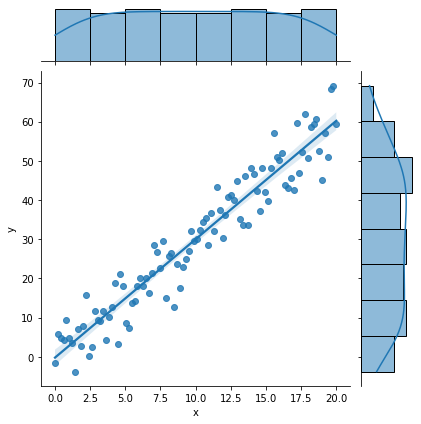

In [54]:
import pandas as pd
# generate data
N = 100
x = np.linspace(0,20,N)
ϵ = np.random.normal(loc = 0.0, scale = 5.0, size = N)
y = 3*x + ϵ 
df = pd.DataFrame({"x":x, "y":y})

import seaborn as sns
g = sns.jointplot(x="x", y="y", data=df, kind="reg")

       coef
b -0.227026
m  3.022704


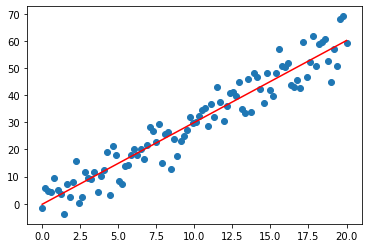

In [55]:
# let’s start with some random coefficient guesses and optimize
from scipy.optimize import minimize
guess1 = np.array([5,5])
results1 = minimize(MLELinearRegression, guess1)
resultsdf1 = pd.DataFrame({'coef':results1['x']})
resultsdf1.index=['b','m']   
print(resultsdf1)

plt.plot(x, resultsdf1["coef"]["m"]*x+resultsdf1["coef"]["b"], color = "red") 
plt.scatter(x,y)

Folie 42 ML-Schätzer

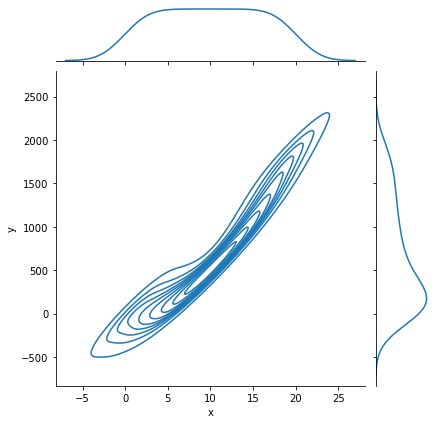

In [60]:
def MLEMultipleRegression(params):
    a, b, c = params[0], params[1], params[2]
    yhat = a*x**2+b*x+c 
    negLL = -np.sum(stats.norm.logpdf(y, loc=yhat) )
    return(negLL)

import pandas as pd
# generate data
N = 100
x = np.linspace(0,20,N)
ϵ = np.random.normal(loc = 0.0, scale = 5.0, size = N)
y = 5*x**2-2*x+ 4+ ϵ
df = pd.DataFrame({"x":x, "y":y})

import seaborn as sns
g = sns.jointplot(x="x", y="y", data=df, kind="kde")

In [57]:
# let’s start with some random coefficient guesses and optimize
from scipy.optimize import minimize
guess = np.array([5,5,5])
results = minimize(MLEMultipleRegression, guess, method = "CG")

resultsdf = pd.DataFrame({'coef':results['x']})
resultsdf.index=['a','b',"c"]   
resultsdf

,coef
a,5.031285
b,-2.665314
c,6.147277


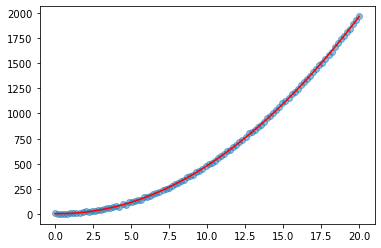

In [58]:
plt.plot(x,resultsdf["coef"]["a"]*x**2+resultsdf["coef"]["b"]*x+resultsdf["coef"]["c"], color = "red")
plt.scatter(x,y, alpha = 0.5)

Folie 46

In [65]:
# generate data
N = 100
x = np.linspace(0,20,N)
ϵ = np.random.normal(loc = 0.0, scale = 5.0, size = N)
y = 3*x + ϵ 
df = pd.DataFrame({"x":x, "y":y})

import pymc3 as pm

basic_model = pm.Model()

with basic_model:

    # Priors for unknown model parameters
    m = pm.Normal('m', mu=0, sigma=10)
    b = pm.Normal('b', mu=0, sigma=10)
    ϵ_m = pm.HalfNormal('error', sigma=5)

    # Expected value of outcome
    mu = m*x + b

    # Likelihood (sampling distribution) of observations
    Y_obs = pm.Normal('Y_obs', mu=mu, sigma=ϵ_m, observed=y)
    
map_estimate = pm.find_MAP(model=basic_model)

print(map_estimate)

C:\Users\chris\anaconda3\lib\site-packages\theano\tensor\elemwise.py:826: RuntimeWarning: divide by zero encountered in log
  variables = ufunc(*ufunc_args, **ufunc_kwargs)
C:\Users\chris\anaconda3\lib\site-packages\theano\tensor\elemwise.py:826: RuntimeWarning: invalid value encountered in multiply
  variables = ufunc(*ufunc_args, **ufunc_kwargs)
C:\Users\chris\anaconda3\lib\site-packages\theano\tensor\elemwise.py:826: RuntimeWarning: invalid value encountered in log
  variables = ufunc(*ufunc_args, **ufunc_kwargs)



{'m': array(3.0487722), 'b': array(-1.15437114), 'error_log__': array(1.54548382), 'error': array(4.6902403)}


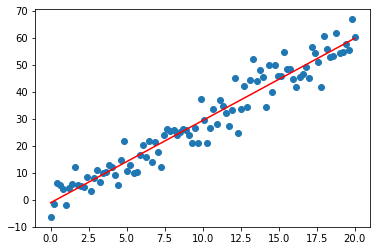

In [67]:
plt.plot(x, map_estimate["m"]*x+map_estimate["b"], color ="red")
plt.scatter(x, y)

Folie 47

In [68]:
with basic_model:
    # draw 500 posterior samples
    trace = pm.sample(500)

C:\Users\chris\AppData\Local\Temp/ipykernel_15740/530112407.py:3: FutureWarning: In v4.0, pm.sample will return an `arviz.InferenceData` object instead of a `MultiTrace` by default. You can pass return_inferencedata=True or return_inferencedata=False to be safe and silence this warning.
  trace = pm.sample(500)
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
C:\Users\chris\anaconda3\lib\site-packages\theano\tensor\elemwise.py:826: RuntimeWarning: divide by zero encountered in log
  variables = ufunc(*ufunc_args, **ufunc_kwargs)
C:\Users\chris\anaconda3\lib\site-packages\theano\tensor\elemwise.py:826: RuntimeWarning: invalid value encountered in multiply
  variables = ufunc(*ufunc_args, **ufunc_kwargs)
C:\Users\chris\anaconda3\lib\site-packages\theano\tensor\elemwise.py:826: RuntimeWarning: invalid value encountered in log
  variables = ufunc(*ufunc_args, **ufunc_kwargs)
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [error, b, m]


Sampling 4 chains for 1_000 tune and 500 draw iterations (4_000 + 2_000 draws total) took 176 seconds.


In [69]:
pm.summary(trace).round(2)

C:\Users\chris\anaconda3\lib\site-packages\arviz\data\io_pymc3.py:96: FutureWarning: Using `from_pymc3` without the model will be deprecated in a future release. Not using the model will return less accurate and less useful results. Make sure you use the model argument or call from_pymc3 within a model context.
  warnings.warn(


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
m,3.04,0.08,2.89,3.20,0.00,0.00,850.0,936.0,1.01
b,-1.10,0.98,-2.94,0.73,0.03,0.02,846.0,945.0,1.00
error,4.78,0.35,4.19,5.46,0.01,0.01,1105.0,1060.0,1.00


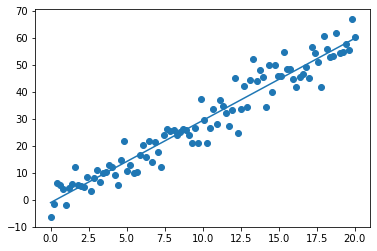

In [70]:
plt.plot(x, trace['m'].mean()*x+trace['b'].mean())
plt.scatter(x, y)